<a href="https://colab.research.google.com/github/iarapineda/Ciencia-y-anal-tica-de-datos-Sep2026/blob/main/Actividad8RLineal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 8**
Regresión Lineal

---

Iara Pérez Pineda A01705855

Carla Naiely Perez A01285695

Hector Javier Pequeno Chairez A01246364


En esta actividad trabajarás con el archivo `diamonds_dataset.csv`, basado en un conjunto de datos sobre características de diamantes, disponible en el paquete ggplot2 de R y en repositorios públicos de análisis de datos.

Los datos fueron recopilados para analizar el precio de los diamantes en función de sus propiedades físicas y cualidades de corte, color y claridad. Los indicadores incluidos son:

* `carat`: Peso del diamante en quilates
* `cut`: Calidad del corte del diamante (Fair, Good, Very Good, Premium, Ideal)
* `color`: Color del diamante, de D (mejor) a J (peor)
* `clarity`: Claridad del diamante (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF)
* `depth`: Profundidad total del diamante como porcentaje: z / mean(x, y)
* `table`: Ancho de la tabla del diamante como porcentaje de x
* `x`: Longitud en mm
* `y`: Ancho en mm
* `z`: Profundidad en mm
* `price`: Precio del diamante en dólares estadounidenses. Es la variable de salida o *target*

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [18]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error, r2_score

1. Descarga el archivo: `diamonds_dataset.csv` y guarda, en un dataframe (`diamonds_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.

In [19]:

diamonds_df = pd.read_csv("diamonds_dataset.csv")

diamonds_df.info()

display(diamonds_df.nunique())
display(diamonds_df.isna().sum())

print("Registros duplicados:", diamonds_df.duplicated().sum())

diamonds_df = diamonds_df.drop_duplicates().reset_index(drop=True)

print("Dimensiones finales:", diamonds_df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53916 entries, 0 to 53915
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53916 non-null  float64
 1   cut      53916 non-null  object 
 2   color    53916 non-null  object 
 3   clarity  53916 non-null  object 
 4   depth    53916 non-null  float64
 5   table    53916 non-null  float64
 6   x        53916 non-null  float64
 7   y        53916 non-null  float64
 8   z        53916 non-null  float64
 9   price    53916 non-null  int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


,0
carat,271
cut,5
color,7
clarity,8
depth,184
table,127
x,550
y,549
z,371
price,11595


,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
x,0
y,0
z,0
price,0


Registros duplicados: 145
Dimensiones finales: (53771, 10)


El conjunto de datos contiene inicialmente 53,916 registros y 10 columnas, de las cuales 7 son numéricas (*carat, depth, table, x, y, z, price*) y 3 son categóricas (*cut, color, clarity*). El análisis de valores únicos identificó 5 categorías de corte, 7 de color y 8 de claridad. No se encontraron valores faltantes en ninguna columna; sin embargo, se detectaron 145 registros duplicados, los cuales fueron eliminados y se reinició el índice. Como resultado, el dataframe final contiene 53,771 registros, conservando las 10 variables originales para los análisis posteriores.

2. Obtén las estadísticas descriptivas, separando las variables numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Para las variables numéricas genera histogramas y boxplots para explorar la distribución y la dispersión.
* Para las variables categóricas utiliza diagramas de barras para visualizar la frecuencia de cada categoría.

In [20]:

numericas = diamonds_df.select_dtypes(include="number").columns
categoricas = diamonds_df.select_dtypes(include="object").columns

display(diamonds_df[numericas].describe())
display(diamonds_df[categoricas].describe())

for col in categoricas:
    print(col)
    display(diamonds_df[col].value_counts().to_frame("Frecuencia"))


,carat,depth,table,x,y,z,price
count,53771.000000,53771.000000,53771.000000,53771.000000,53771.000000,53771.000000,53771.000000
mean,0.797323,61.748160,57.457635,5.731280,5.734618,3.539774,3930.320545
std,0.472474,1.429519,2.233192,1.118102,1.138982,0.701677,3984.687429
min,0.200000,43.000000,43.000000,3.730000,3.680000,1.070000,326.000000
25%,0.400000,61.000000,56.000000,4.710000,4.720000,2.910000,951.000000
50%,0.700000,61.800000,57.000000,5.700000,5.710000,3.530000,2401.000000
75%,1.040000,62.500000,59.000000,6.540000,6.540000,4.030000,5323.500000
max,4.500000,79.000000,95.000000,10.230000,58.900000,31.800000,18823.000000


,cut,color,clarity
count,53771,53771,53771
unique,5,7,8
top,Ideal,G,SI1
freq,21485,11254,13030


cut


,Frecuencia
cut,
Ideal,21485
Premium,13737
Very Good,12065
Good,4888
Fair,1596


color


,Frecuencia
color,
G,11254
E,9776
F,9517
H,8266
D,6753
I,5404
J,2801


clarity


,Frecuencia
clarity,
SI1,13030
VS2,12225
SI2,9140
VS1,8155
VVS2,5056
VVS1,3646
IF,1784
I1,735


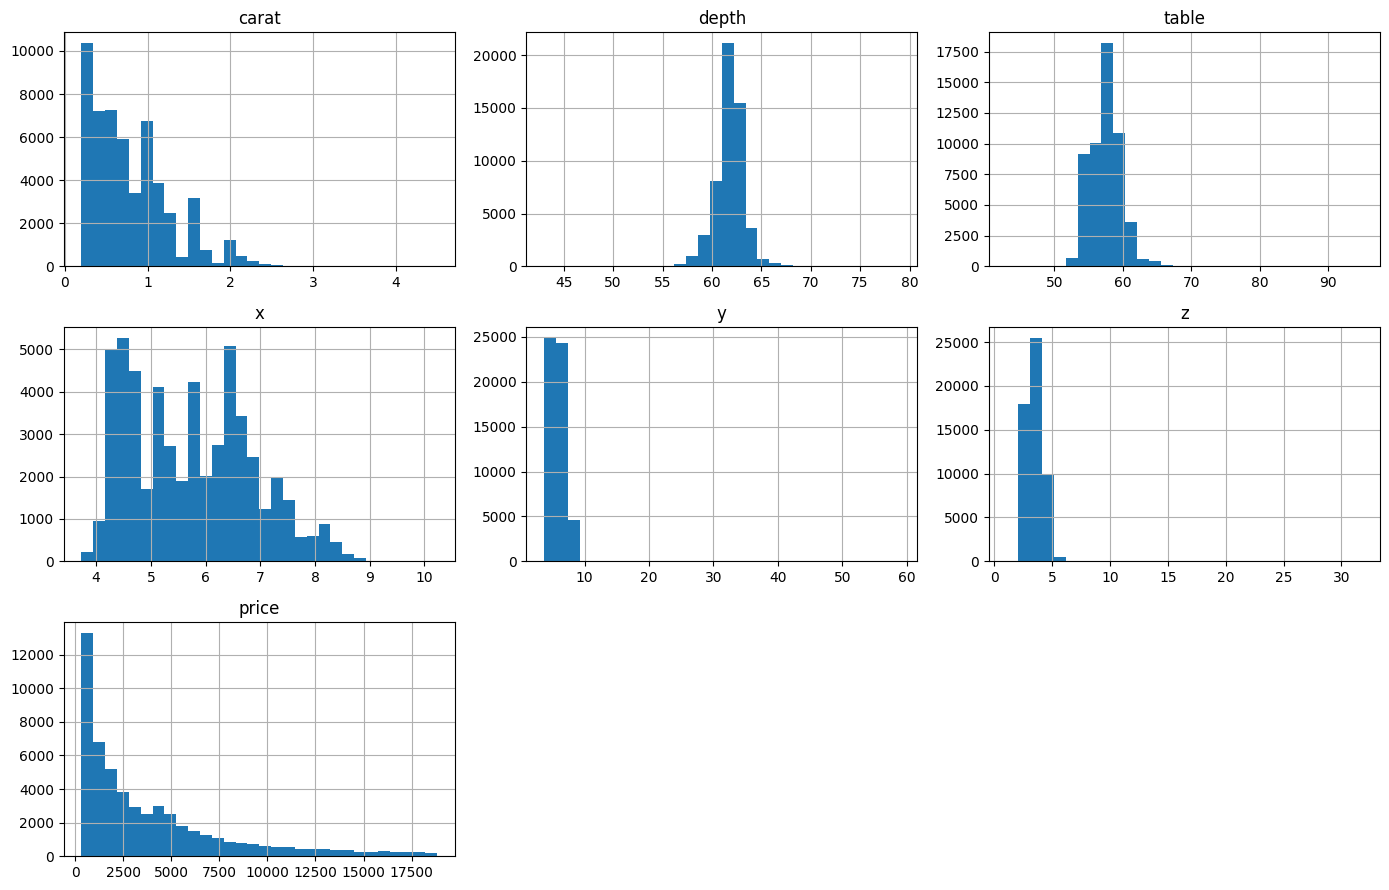

In [21]:

diamonds_df[numericas].hist(bins=30, figsize=(14, 9))
plt.tight_layout()
plt.show()


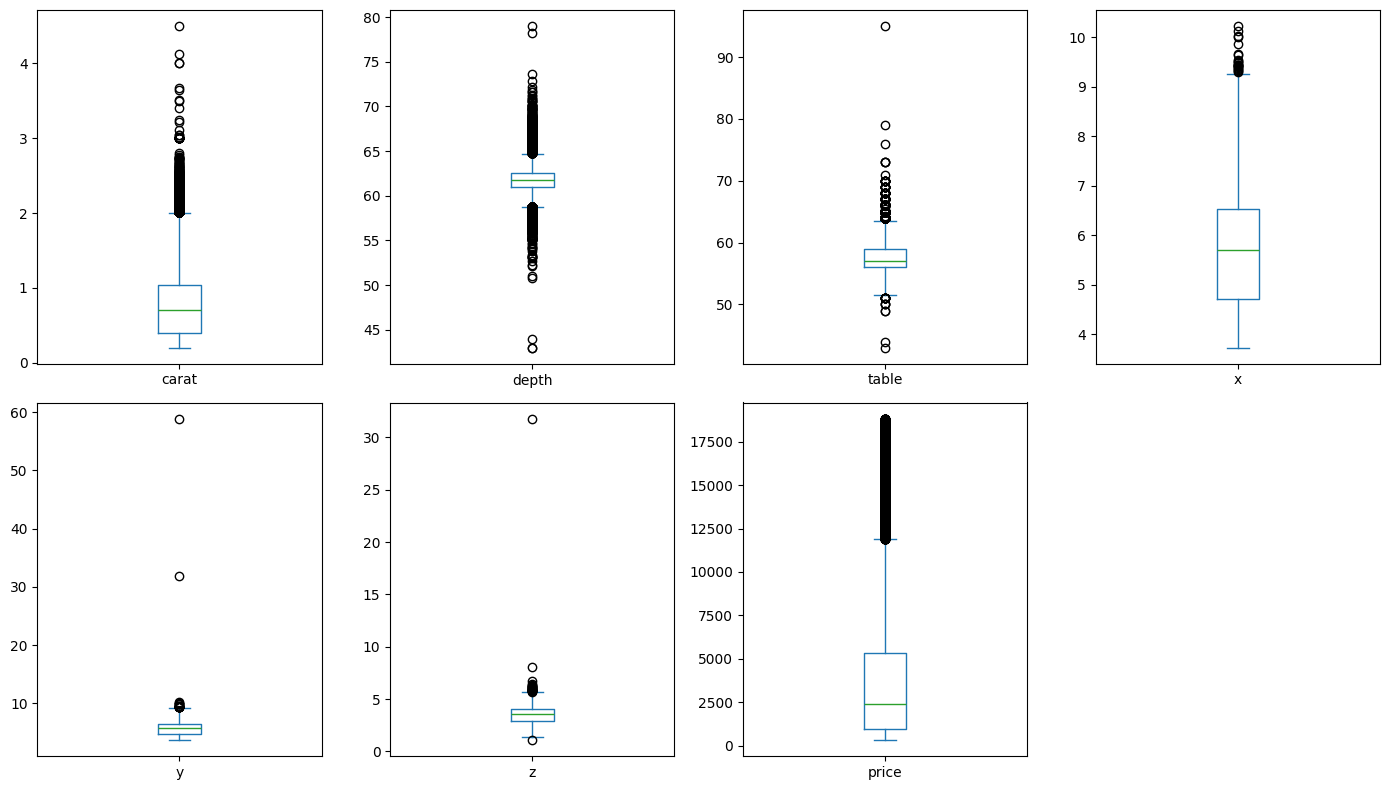

In [22]:

diamonds_df[numericas].plot(
    kind="box",
    subplots=True,
    layout=(2, 4),
    figsize=(14, 8),
    sharey=False
)
plt.tight_layout()
plt.show()


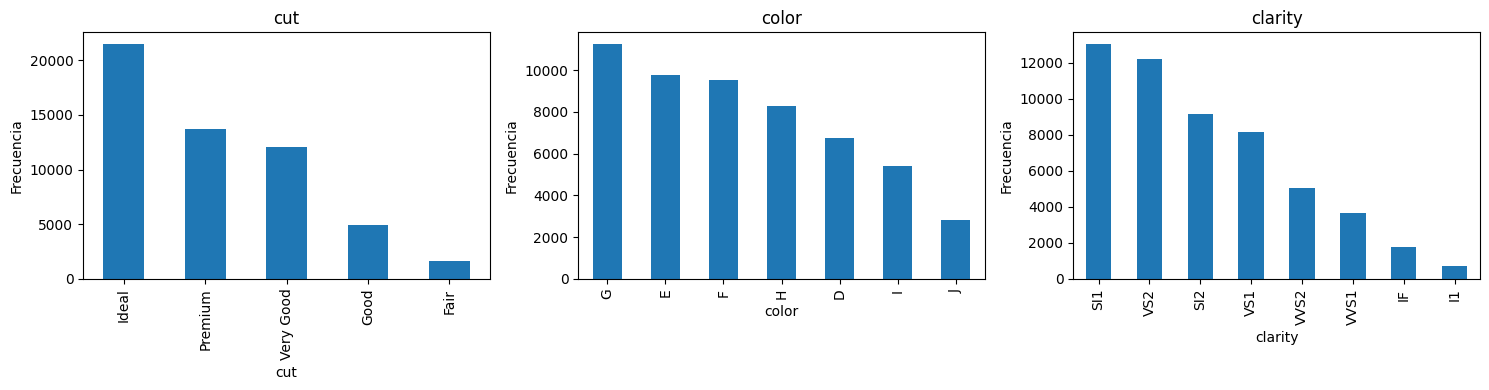

In [23]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(categoricas):
    diamonds_df[col].value_counts().plot.bar(ax=axes[i], title=col)
    axes[i].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()


### Análisis univariado

El análisis descriptivo de las variables numéricas muestra que el peso promedio de los diamantes es de 0.797 quilates, mientras que el precio promedio es de aproximadamente $3,930.32 USD, con una mediana de $2,401 USD. Esta diferencia indica una distribución asimétrica hacia la derecha, donde una menor cantidad de diamantes presenta precios considerablemente elevados.

Los histogramas muestran una mayor concentración de diamantes en los valores bajos de peso y precio. Por su parte, los boxplots permiten identificar valores atípicos en distintas variables, especialmente en el precio, el peso y algunas dimensiones físicas, así que estos valores podrían influir en los modelos predictivos posteriores.

En cuanto a las variables categóricas, la calidad de corte más frecuente es *Ideal*, con 21,485 registros; el color predominante es *G*, con 11,254 registros; y la claridad más común es *SI1*, con 13,030 registros. Los diagramas de barras permiten observar estas diferencias de frecuencia entre categorías.

En conjunto el análisis evidencia que las variables presentan distintas distribuciones y escalas, lo cual será importante considerar durante el preprocesamiento y la construcción de los modelos de regresión.

3. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Boxplots que muestren la distribución del precio para cada categoría de color, asegurándose de que las categorías se muestren en el orden de calidad de diamante de mejor a peor: D, E, F, G, H, I, J.
* ¿La tendencia de los precios se comporta como esperabas? Identifica si alguna otra variable podría estar influyendo en la tendencia observada por color y comenta tus observaciones.
* Gráfico de dispersión del precio frente al peso de los diamantes, coloreando los puntos según la categoría de calidad del corte.
* ¿Qué relación se observa entre el peso del diamante y su precio según la calidad del corte?

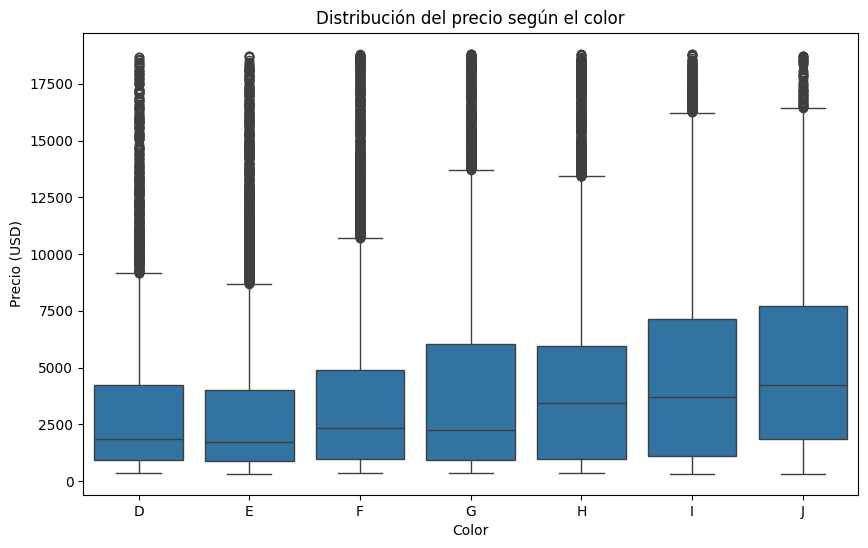

In [24]:

plt.figure(figsize=(10, 6))

sns.boxplot(data=diamonds_df, x="color", y="price",
            order=["D", "E", "F", "G", "H", "I", "J"])

plt.title("Distribución del precio según el color")
plt.xlabel("Color")
plt.ylabel("Precio (USD)")
plt.show()


La distribución del precio según el color presenta una tendencia distinta a la esperada, ya que los diamantes de menor calidad de color (H, I y J) muestran generalmente precios más elevados que aquellos de mejor calidad (D y E). Sin embargo, esto no significa que una menor calidad de color aumente el precio. Una posible explicación es la influencia del peso (*carat*), dado que los diamantes de las categorías I y J presentan, en promedio, mayor peso que los de las categorías D y E. Por lo tanto, el precio no depende únicamente del color, sino de la combinación de distintas características físicas y de calidad.

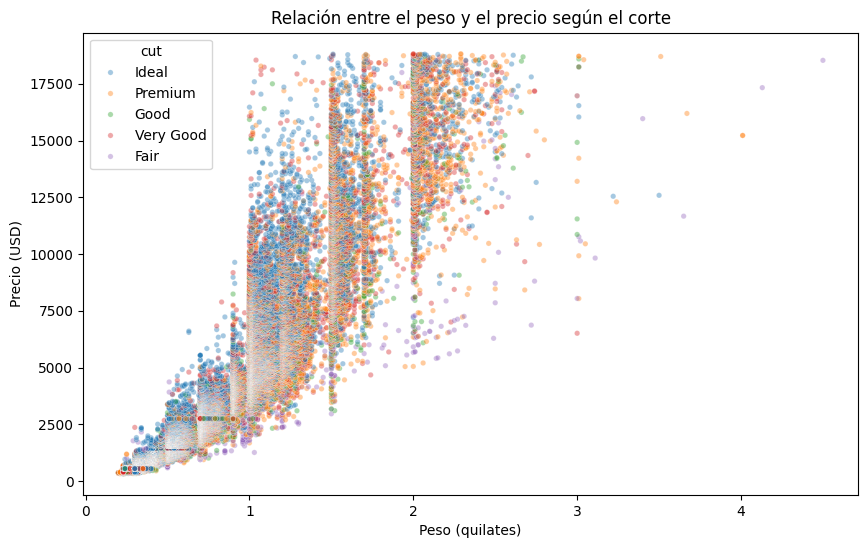

In [25]:

plt.figure(figsize=(10, 6))

sns.scatterplot(data=diamonds_df, x="carat", y="price",
                hue="cut", alpha=0.4, s=15)

plt.title("Relación entre el peso y el precio según el corte")
plt.xlabel("Peso (quilates)")
plt.ylabel("Precio (USD)")
plt.show()


Se observa una relación positiva entre el peso y el precio de los diamantes: a medida que aumenta el número de quilates, el precio tiende a incrementarse. Sin embargo, esta relación presenta dispersión, especialmente entre los diamantes de mayor peso, lo que indica que otros factores también influyen en el precio. Al distinguir los puntos según la calidad del corte, se observa que diferentes categorías pueden presentar precios distintos para pesos similares. Por lo tanto, el peso parece ser una variable predictora importante, aunque la calidad del corte y otras propiedades deben considerarse para explicar mejor las diferencias de precio.

4. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Analiza la correlación entre los predictores (excluyendo `price`), identifica si un único predictor captura información que también está presente en varios otros y elimina los predictores redundantes para simplificar la complejidad de los modelos que construirás más adelante.
* Vuelve a generar el mapa de calor para verificar que ya no queden predictores altamente correlacionados.

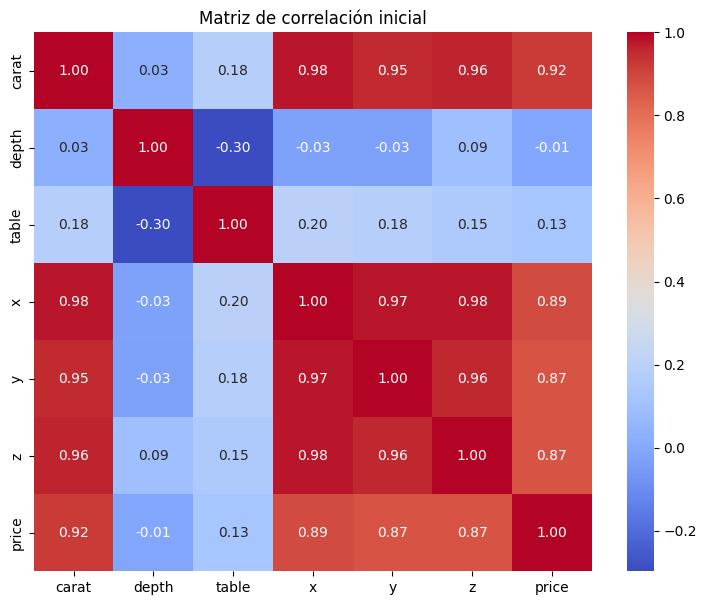

carat  x        0.978108
       y        0.954222
       z        0.961213
       price    0.921846
x      y        0.974799
       z        0.975361
y      z        0.956587
dtype: float64


In [26]:

corr = diamonds_df[numericas].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación inicial")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pares[pares > 0.9])


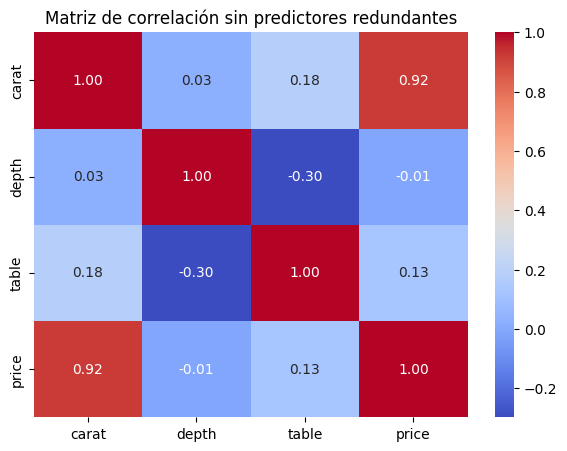

In [27]:

diamonds_df = diamonds_df.drop(columns=["x", "y", "z"])

corr_reducida = diamonds_df.select_dtypes(include="number").corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr_reducida, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación sin predictores redundantes")
plt.show()


### Análisis de correlación

La matriz de correlación muestra relaciones positivas muy fuertes entre las variables *carat*, *x*, *y* y *z*, con coeficientes superiores a 0.9. Esto indica que el peso y las dimensiones físicas de los diamantes comparten información y podrían generar redundancia en los modelos predictivos.

La variable *carat* presenta la correlación más alta con el precio (0.922) por lo que se decidió conservarla y eliminar las variables *x*, *y* y *z*, simplificando el conjunto de predictores y reduciendo posibles problemas de multicolinealidad.

Después de eliminar estas variables se generó una nueva matriz de correlación que confirma que ya no existen correlaciones superiores a 0.9 entre los predictores numéricos restantes. La relación entre *carat* y *price* se mantiene, lo cual es deseable porque representa su capacidad potencial para explicar el precio de los diamantes.

5. Construye un modelo de regresión simple utilizando únicamente la variable predictora que tenga la mayor correlación con `price`. Para ello:
* Asigna esta variable a `X` y `price` a `y` y divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Entrena un modelo con `LinearRegression()` de scikit-learn y evalúalo en el conjunto de prueba utilizando las métricas `RMSE` (Root Mean Squared Error) y `R²` (coeficiente de determinación).
* Añade los valores obtenidos a un dataframe de resultados, que incluya el nombre del modelo (*Baseline*) y una columna para cada métrica.
* Muestra la ecuación de la regresión lineal utilizando el intercepto y el coeficiente asociado al predictor. La ecuación debe tener la forma:
> `price = intercepto + coeficiente × predictor`

In [28]:

X = diamonds_df[["carat"]]
y = diamonds_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

baseline = LinearRegression()
baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred_baseline)
r2 = r2_score(y_test, y_pred_baseline)

resultados = pd.DataFrame({
    "Modelo": ["Baseline"],
    "RMSE": [rmse],
    "R²": [r2]
})

display(resultados)

print(f"price = {baseline.intercept_:.2f} + {baseline.coef_[0]:.2f} x carat")


,Modelo,RMSE,R²
0,Baseline,1532.43849,0.84618


price = -2276.79 + 7792.73 x carat


### Modelo de regresión lineal simple (baseline)

Se construyó un modelo de regresión lineal simple utilizando *carat* como única variable predictora, debido a que presenta la mayor correlación positiva con el precio (0.922). Los datos se dividieron en un 80% para entrenamiento y un 20% para prueba, utilizando `random_state=1`.

El modelo obtuvo un RMSE de 1532.44 USD y un R² de 0.8462, lo que indica que el peso del diamante permite explicar aproximadamente el 84.62% de la variabilidad del precio en el conjunto de prueba. La ecuación obtenida fue:

**price = -2276.79 + 7792.73 × carat**

El coeficiente positivo confirma que existe una relación directa entre el peso y el precio. Sin embargo, el error de predicción indica que el peso por sí solo no explica completamente las diferencias de precio entre los diamantes, por lo que resulta conveniente incorporar otras características en los siguientes modelos. El intercepto negativo corresponde al ajuste matemático y no debe interpretarse como un precio real para un diamante de cero quilates.

6. Utiliza todas las variables como predictoras para crear un segundo modelo:
* Haz la asignación correspondiente en `X` y `y` y divide en entrenamiento y prueba usando la misma configuración del ejercicio anterior.
* Prepara un transformador, denominado `preprocessing`, para aplicar escalamiento robusto a los predictores numéricos y codificación ordinal a los categóricos. Asegúrate de respetar el orden correcto de cada categoría, tal como se indica en la descripción de las variables.
* Construye un pipeline que combine el transformador creado con un modelo de regresión lineal.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Ordinal_Robust*.

In [29]:

X = diamonds_df.drop(columns="price")
y = diamonds_df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

num_cols = ["carat", "depth", "table"]
cat_cols = ["cut", "color", "clarity"]

preprocessing = ColumnTransformer([
    ("num", RobustScaler(), num_cols),
    ("cat", OrdinalEncoder(categories=[
        ["Fair", "Good", "Very Good", "Premium", "Ideal"],
        ["J", "I", "H", "G", "F", "E", "D"],
        ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
    ]), cat_cols)
])

modelo_ordinal = make_pipeline(preprocessing, LinearRegression())
modelo_ordinal.fit(X_train, y_train)

y_pred_ordinal = modelo_ordinal.predict(X_test)

rmse_ordinal = root_mean_squared_error(y_test, y_pred_ordinal)
r2_ordinal = r2_score(y_test, y_pred_ordinal)

resultados = pd.concat([resultados, pd.DataFrame({
    "Modelo": ["Ordinal_Robust"],
    "RMSE": [rmse_ordinal],
    "R²": [r2_ordinal]
})], ignore_index=True)

display(resultados)


,Modelo,RMSE,R²
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016


### Modelo de regresión lineal múltiple (Ordinal_Robust)

Se construyó un modelo de regresión lineal múltiple utilizando seis variables predictoras: *carat, depth, table, cut, color* y *clarity*. Para el preprocesamiento se aplicó RobustScaler a las variables numéricas y OrdinalEncoder a las categóricas, respetando sus jerarquías de calidad. Ambas transformaciones se integraron mediante un pipeline junto con LinearRegression.

El modelo obtuvo un RMSE de 1216.82 USD y un R² de 0.9030, lo que significa que explica aproximadamente el 90.30% de la variabilidad del precio en el conjunto de prueba. En comparación con el modelo Baseline, el error de predicción disminuyó aproximadamente un 20.6%.

Estos resultados indican que incorporar las características físicas y de calidad de los diamantes mejora la capacidad predictiva del modelo respecto al uso exclusivo del peso. No obstante, la codificación ordinal supone una separación uniforme entre categorías, lo cual no necesariamente representa las diferencias reales de calidad.

7. Prepara otro transformador, llamado `preprocessing2`, que aplique escalamiento Min-Max a los predictores numéricos y codificación one-hot a los categóricos, asegurando `drop='first'` para prevenir multicolinealidad en las variables dummies generadas.
* Construye otro pipeline utilizando este nuevo transformador y, a continuación, entrena y evalúa el modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *OHE_MinMax*.

In [30]:

preprocessing2 = ColumnTransformer([
    ("num", MinMaxScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first"), cat_cols)
])

modelo_ohe = make_pipeline(preprocessing2, LinearRegression())
modelo_ohe.fit(X_train, y_train)

y_pred_ohe = modelo_ohe.predict(X_test)

rmse_ohe = root_mean_squared_error(y_test, y_pred_ohe)
r2_ohe = r2_score(y_test, y_pred_ohe)

resultados = pd.concat([resultados, pd.DataFrame({
    "Modelo": ["OHE_MinMax"],
    "RMSE": [rmse_ohe],
    "R²": [r2_ohe]
})], ignore_index=True)

display(resultados)


,Modelo,RMSE,R²
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499


### Modelo de regresión lineal múltiple (OHE_MinMax)

Se construyó un tercer modelo de regresión lineal múltiple utilizando MinMaxScaler para escalar las variables numéricas y OneHotEncoder para transformar las variables categóricas en variables binarias. Se utilizó el parámetro `drop='first'` para evitar redundancias entre las variables dummy generadas.

El modelo obtuvo un RMSE de 1142.52 USD y un R² de 0.9145, explicando aproximadamente el 91.45% de la variabilidad del precio en el conjunto de prueba.

En comparación con el modelo Ordinal_Robust, el RMSE disminuyó aproximadamente un 6.1%, mientras que el R² aumentó de 0.9030 a 0.9145. Esto indica que el nuevo preprocesamiento permitió mejorar las predicciones. Una posible explicación es que OneHotEncoder representa las categorías de manera independiente, sin asumir distancias uniformes entre los distintos niveles de calidad.

8. Modifica el pipeline anterior para emplear regresión polinomial de segundo grado y evalúa si esto mejora el ajuste del modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *PolynomialDegree2*.

In [31]:

modelo_polinomial = make_pipeline(
    preprocessing2,
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

modelo_polinomial.fit(X_train, y_train)

y_pred_polinomial = modelo_polinomial.predict(X_test)

rmse_polinomial = root_mean_squared_error(y_test, y_pred_polinomial)
r2_polinomial = r2_score(y_test, y_pred_polinomial)

resultados = pd.concat([resultados, pd.DataFrame({
    "Modelo": ["PolynomialDegree2"],
    "RMSE": [rmse_polinomial],
    "R²": [r2_polinomial]
})], ignore_index=True)

display(resultados)


,Modelo,RMSE,R²
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499
3,PolynomialDegree2,749.036382,0.963250


### Modelo de regresión polinomial (PolynomialDegree2)

Se construyó un modelo de regresión polinomial de segundo grado a partir del pipeline anterior, conservando el escalamiento Min-Max y la codificación one-hot. Se incorporó PolynomialFeatures con grado 2 para generar términos cuadráticos e interacciones entre las variables predictoras.

El modelo obtuvo un RMSE de aproximadamente 749.02 USD y un R² de 0.9633, explicando el 96.33% de la variabilidad del precio en el conjunto de prueba.

En comparación con el modelo OHE_MinMax, el RMSE disminuyó aproximadamente un 34.4%, lo que representa una mejora considerable en la precisión de las predicciones. Estos resultados sugieren que la relación entre las características de los diamantes y su precio no es completamente lineal, por lo que incorporar términos polinómicos permite representar mejor su comportamiento.

9. Ordena el dataframe de resultados según el `R²`, de manera que el modelo con mejor desempeño aparezca primero.
* Para dicho modelo, crea un gráfico de dispersión de los valores reales frente a los predichos, e incluye una línea diagonal de referencia para indicar una predicción perfecta.

,Modelo,RMSE,R²
0,PolynomialDegree2,749.036382,0.963250
1,OHE_MinMax,1142.519131,0.914499
2,Ordinal_Robust,1216.822219,0.903016
3,Baseline,1532.438490,0.846180


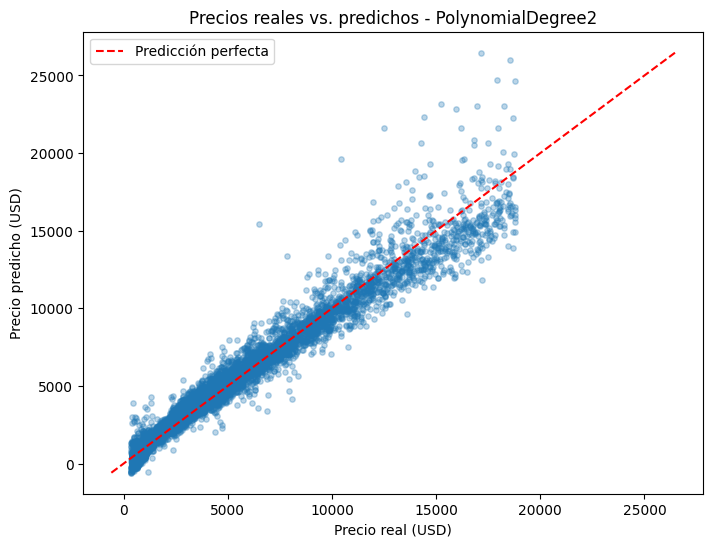

In [32]:

resultados = resultados.sort_values(by="R²", ascending=False).reset_index(drop=True)

display(resultados)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_polinomial, alpha=0.3, s=15)

limites = [min(y_test.min(), y_pred_polinomial.min()),
           max(y_test.max(), y_pred_polinomial.max())]

plt.plot(limites, limites, "r--", label="Predicción perfecta")

plt.title("Precios reales vs. predichos - PolynomialDegree2")
plt.xlabel("Precio real (USD)")
plt.ylabel("Precio predicho (USD)")
plt.legend()
plt.show()


### Comparación y visualización del mejor modelo

Al ordenar los modelos según el coeficiente de determinación (R²), se identificó que PolynomialDegree2 presenta el mejor desempeño, con un R² de 0.9633 y un RMSE de 749.04 USD. Le siguen OHE_MinMax, Ordinal_Robust y Baseline.

El modelo polinomial explica aproximadamente el 96.33% de la variabilidad del precio en el conjunto de prueba, lo que demuestra una mejora considerable respecto a los modelos lineales anteriores.

El gráfico de dispersión de los valores reales frente a los predichos permite evaluar visualmente la precisión del modelo. Los puntos cercanos a la línea diagonal representan predicciones más precisas, mientras que aquellos más alejados muestran errores de estimación.

En conjunto, los resultados indican que incorporar términos polinómicos de segundo grado permite representar mejor las relaciones entre las características de los diamantes y sus precios.

10. Muestra la representación gráfica del pipeline para ubicar la posición de cada elemento dentro del flujo del modelo.
* Obtén los nombres de todas las columnas después del preprocesamiento (numéricas y dummies de categóricas).
* Extrae los nombres de las columnas polinómicas.
* Recupera los coeficientes y el intercepto del modelo de regresión lineal.
* Ordena los coeficientes por su valor absoluto para mostrar los 10 más importantes y da conclusiones sobre cómo los distintos factores influyen en el precio.

In [33]:

from sklearn import set_config

set_config(display="diagram")
display(modelo_polinomial)

columnas_pre = modelo_polinomial.named_steps["columntransformer"].get_feature_names_out()
columnas_poly = modelo_polinomial.named_steps["polynomialfeatures"].get_feature_names_out(columnas_pre)

display(pd.DataFrame({"Columnas preprocesadas": columnas_pre}))
display(pd.DataFrame({"Columnas polinómicas": columnas_poly}))

regresion = modelo_polinomial.named_steps["linearregression"]

print("Intercepto:", regresion.intercept_)

coeficientes = pd.DataFrame({
    "Variable": columnas_poly,
    "Coeficiente": regresion.coef_
})

coeficientes["Magnitud"] = coeficientes["Coeficiente"].abs()

display(coeficientes.sort_values("Magnitud", ascending=False).head(10))


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', MinMaxScaler(),
                                                  ['carat', 'depth', 'table']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['cut', 'color',
                                                   'clarity'])])),
                ('polynomialfeatures', PolynomialFeatures(include_bias=False)),
                ('linearregression', LinearRegression())])

,Columnas preprocesadas
0,num__carat
1,num__depth
2,num__table
3,cat__cut_Good
4,cat__cut_Ideal
5,cat__cut_Premium
6,cat__cut_Very Good
7,cat__color_E
8,cat__color_F
9,cat__color_G


,Columnas polinómicas
0,num__carat
1,num__depth
2,num__table
3,cat__cut_Good
4,cat__cut_Ideal
...,...
225,cat__clarity_VS2 cat__clarity_VVS1
226,cat__clarity_VS2 cat__clarity_VVS2
227,cat__clarity_VVS1^2
228,cat__clarity_VVS1 cat__clarity_VVS2


Intercepto: -909.4923765839671


,Variable,Coeficiente,Magnitud
20,num__carat^2,55139.394904,55139.394904
33,num__carat cat__clarity_IF,49901.020444,49901.020444
38,num__carat cat__clarity_VVS1,46676.274624,46676.274624
39,num__carat cat__clarity_VVS2,44778.777980,44778.777980
36,num__carat cat__clarity_VS1,40030.561597,40030.561597
37,num__carat cat__clarity_VS2,37092.171153,37092.171153
34,num__carat cat__clarity_SI1,31996.333902,31996.333902
35,num__carat cat__clarity_SI2,24370.410622,24370.410622
32,num__carat cat__color_J,-20648.946158,20648.946158
31,num__carat cat__color_I,-14266.529952,14266.529952


### Interpretación del modelo polinomial

El pipeline del modelo PolynomialDegree2 está compuesto por tres etapas: preprocesamiento mediante MinMaxScaler y OneHotEncoder, generación de características polinómicas de segundo grado y entrenamiento mediante LinearRegression.

El preprocesamiento produjo 20 características, que posteriormente se expandieron a 230 términos polinómicos. El intercepto obtenido fue de aproximadamente −909.49.

Al ordenar los coeficientes por su valor absoluto, el término cuadrático del peso (*carat²*) presentó la mayor magnitud, con un coeficiente positivo de aproximadamente 55,139.39. También destacaron las interacciones del peso con distintas categorías de claridad, cuyos coeficientes fueron positivos, mientras que las interacciones del peso con los colores I y J presentaron coeficientes negativos.

Estos resultados sugieren que el peso del diamante tiene una relación importante con el precio y que dicha relación varía según características como la claridad y el color. Sin embargo, los coeficientes corresponden a variables transformadas y algunos términos polinómicos son redundantes, por lo que sus magnitudes no deben interpretarse directamente como efectos independientes o causales.

En conclusión, el modelo polinomial permite representar relaciones más complejas entre las características de los diamantes y su precio. Esto es consistente con su mejor desempeño en el conjunto de prueba, donde obtuvo un R² de 0.9633 y un RMSE de aproximadamente 749.04 USD.

### Declaración de uso de inteligencia artificial

Se utilizó chatgpt como herramienta de apoyo para la revisión y depuración de código así como apoyo para el estudio de las interpretaciones y análisis.


OpenAI. (2026). ChatGPT (GPT-6) [Modelo de lenguaje grande]. https://chatgpt.com/